---
INFO
---
Name: Kiarash Akbari

Date: 1404-10-8

---
SETUP
----

In [45]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import os

sns.set(style='whitegrid')
np.random.seed(42)

DATA_DIR = 'data'

os.makedirs(DATA_DIR, exist_ok=True)

print(f"directories '{DATA_DIR}' is ready")


directories 'data' is ready


---
DATA CREATION
----

In [46]:
#creating data sets using ai
def create_relational_data():
    np_patients = 1000

    demographics = pd.DataFrame({
        'patient_id': range(1, np_patients + 1),
        'age': np.append(np.random.randint(18, 90, np_patients-10), [150, 999, 102, 110, 105, 999, 120, -5, 200, 999]),
        'gender': np.random.choice(['Female', 'Male'], np_patients)
    })

    n_treat = 900
    treatments = pd.DataFrame({
        'patient_id':np.random.choice(range(1, np_patients + 1), n_treat, replace=False),
        'doctor_id':np.random.choice(['Dr. A', 'Dr. B', 'Dr. C', 'Dr. D'], n_treat),
        'visit_type':np.random.choice(['Routine', 'Emergency', 'Follow-up'], n_treat),
        'speciality':np.random.choice(['CBT', 'Psychoanalysis', 'Family Therapy'], n_treat),
        'adherence':np.append(np.random.normal(80, 10, n_treat-5), [120, 150, 110, 105, 130]),
        'risk_score':np.random.normal(50, 10, n_treat),
        'participation_score':np.random.randint(0, 100, n_treat),
        'dosage_10mg':np.random.normal(5, 2, n_treat),
        'dosage_20mg': np.random.normal(3, 1.5, n_treat),
        'disease_control':np.random.choice(['Controlled', 'Not Controlled'], n_treat)
    })

    demographics.to_csv(os.path.join(DATA_DIR, 'demographics.csv'), index=False)
    treatments.to_csv(os.path.join(DATA_DIR, 'treatments.csv'), index=False)
    print("dummy data created: 'demographics.csv' and 'treatments.csv' in 'data/' folder.")

create_relational_data()

dummy data created: 'demographics.csv' and 'treatments.csv' in 'data/' folder.


---
PIPELINE (QUESTION 3 - 4)
---

In [47]:
def load_data(data):
    path = os.path.join(DATA_DIR, data)
    return pd.read_csv(path)

def check_db_integrity(df1, df2, key):
    if df1[key].duplicated().any() or df2[key].duplicated().any():
        print(f"duplicate in table (key: {key})")
    
    missing_ids = set(df1[key]) - set(df2[key])
    if missing_ids:
        print(f"warning {len(missing_ids)} missing treatments")
    
def clean_data(df):
    df_clean = df.copy()
    df_clean = df_clean[df_clean['age'] <= 99]
    df_clean.loc[df_clean['adherence'] > 100, 'adherence'] = 100
    df_clean = df_clean.ffill()
    
    print('finished data cleaning')
    return df_clean

def build_features(df):
    df_new = df.copy()
    df_new['age_group'] = pd.cut(df_new['age'], 
                                 bins=[0, 35, 60, 100], 
                                 labels=['young', 'middle', 'senior'])
    df_new['is_high_risk'] = df_new['risk_score'] > 60
    
    print("finished building features")
    return df_new

print("loading data...")
demo_df = load_data('demographics.csv')
treat_df = load_data('treatments.csv')

check_db_integrity(demo_df, treat_df, 'patient_id')

merged_df = pd.merge(demo_df, treat_df, on='patient_id', how='inner')

cleaned_df = clean_data(merged_df)
final_df = build_features(cleaned_df)

final_df.to_csv(os.path.join(DATA_DIR, 'processed_final.csv'), index=False )
print(f"pipeline complete. \nfinal data frame shape: {final_df.shape}")

loading data...
warning 100 missing treatments
finished data cleaning
finished building features
pipeline complete. 
final data frame shape: (894, 14)



Database Logic & Schema Analysis


Entities (موجودیت ها)

demographics: جدول Master

PK: patient_id (باید Unique باشد)

treatments: جدول Transactional

FK: patient_id (رفرنس به جدول Master)

Relationships (روابط)
<div dir="rtl" style="text-align: right;">

ارتباط بین دو جدول از نوع 1:1 روی ستون patient_id است.

عملیات: Inner Join روی patient_id

Integrity Checks (قبل از Merge) برای جلوگیری از دیتاهای کثیف (Dirty Data)، موارد زیر چک می شود:

Duplication: بررسی تکراری نبودن patient_id در هر دو جدول (Cardinality Check)

Orphan Records: اطمینان از اینکه تمام patient_id های جدول treatments در demographics موجود هستند (Referential Integrity)

<div align="center">

</div>

</div>

---
QUESTION 2
---

part a: demographics


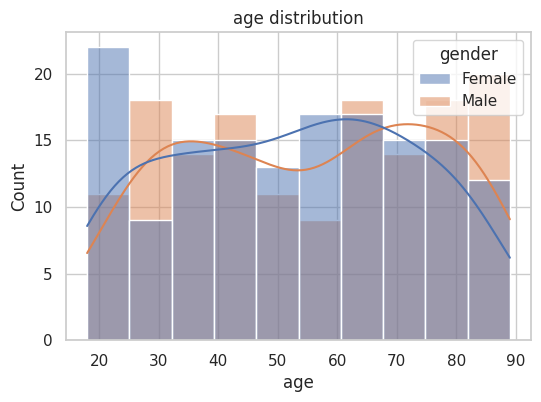


part b: gender vs visit type
p-value: 0.6083
result: no relationship

part c: gender vs speciality
p-value: 0.4065

part d: dosage 10mg difference
p-value: 0.0756

part e: participation score
p-value: 0.3682
result: no difference

part f: risk score
p-value: 0.1538

partg: disease control
p-value: 0.7290


In [48]:
# select 150 males and 150 females
sample_df =  final_df.groupby('gender').sample(n=150 , random_state=42)

# separating groups 
males = sample_df[sample_df['gender'] =='Male']
females= sample_df[sample_df['gender'] == 'Female']

print("part a: demographics")

plt.figure(figsize=(6, 4))
sns.histplot(data=sample_df, x='age', hue='gender', kde=True)
plt.title('age distribution')
plt.show()

print("\npart b: gender vs visit type")
# creating cross table
ct_visit = pd.crosstab(sample_df['gender'],sample_df['visit_type'])
# p-value 
p_visit = stats.chi2_contingency(ct_visit)[1]
print(f"p-value: {p_visit:.4f}")
if p_visit < 0.05: print("result: there is relationship")
else: print("result: no relationship")

print("\npart c: gender vs speciality")
ct_spec  = pd.crosstab(sample_df['gender'], sample_df['speciality'])
p_spec = stats.chi2_contingency(ct_spec)[1]
print(f"p-value: {p_spec:.4f}")

print("\npart d: dosage 10mg difference")
# comparing 
p_dose =  stats.ttest_ind(males['dosage_10mg'] , females['dosage_10mg'])[1]
print(f"p-value: {p_dose:.4f}")

print("\npart e: participation score")
p_part = stats.ttest_ind(males['participation_score'], females['participation_score'])[1]
print(f"p-value: {p_part:.4f}")
if p_part < 0.10: print("result: there is difference")
else: print("result: no difference")

print("\npart f: risk score")
p_risk = stats.ttest_ind(males['risk_score'], females['risk_score'])[1]
print(f"p-value: {p_risk:.4f}")

print("\npartg: disease control")
ct_control = pd.crosstab(sample_df['gender'], sample_df['disease_control'])
p_control = stats.chi2_contingency(ct_control)[1]
print(f"p-value: {p_control:.4f}")


---
QUESTION 3
---

In [49]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

#select 4 random doctors
docs = final_df['doctor_id'].unique()
sel_docs = np.random.choice(docs, 4, replace=False)
print(f"selected doctors: {sel_docs}")

#filter data for these doctors
df_doc = final_df[final_df['doctor_id'].isin(sel_docs)]

#sample 50 patients per doctor
df_50 = df_doc.groupby('doctor_id', group_keys=False).apply(lambda x: x.sample(50, random_state=42))

#part a: doctor preference
print("\npart a: doctor preference")
ct = pd.crosstab(df_50['doctor_id'], df_50['speciality'])
p = stats.chi2_contingency(ct)[1]
print(f"p-value: {p:.4f}")

#part b: risk score
print("\npart: risk score")
groups = [g['risk_score'].values for _, g in df_50.groupby('doctor_id')]
p_anova =stats.f_oneway(*groups)[1]
print(f"p-value: {p_anova:.4f}")

#part c: success rate
print("\npart c: success rate")
ct = pd.crosstab(df_50['doctor_id'], df_50['disease_control'])
p = stats.chi2_contingency(ct)[1]
print(f"p-value: {p:.4f}")

#part d: resample with n = 25
print("\npart d: resample n = 25")
df_25= df_doc.groupby('doctor_id', group_keys=False).apply(lambda x: x.sample(25, random_state=42))

#anova for n = 25
groups_25 = [g['risk_score'].values for _, g in df_25.groupby('doctor_id')]
p_25= stats.f_oneway(*groups_25)[1]
print(f"p-value(n=25): {p_25:.4f}")

selected doctors: ['Dr. A' 'Dr. C' 'Dr. B' 'Dr. D']

part a: doctor preference
p-value: 0.7470

part: risk score
p-value: 0.7997

part c: success rate
p-value: 0.5114

part d: resample n = 25
p-value(n=25): 0.9151


---
QUESTION 7
---
<div dir="rtl" style="text-align: right;">
 گزارش تحلیل نهایی و ریسک های داده

 ۱. خلاصه یافته های کلیدی
 
 تحلیل جنسیتی: بررسی ها نشان داد که تفاوت معناداری بین زنان و مردان در میزان مصرف دوز دارو و امتیاز مشارکت وجود ندارد.  

 عملکرد پزشکان: تفاوت معناداری بین پزشکان از نظر موفقیت درمان یا ریسک بیماران مشاهده نشد.

 اثر حجم نمونه: کاهش تعداد نمونه از ۵۰ به ۲۵، باعث کاهش توان آزمون آماری شد و تشخیص تفاوت ها را سخت تر کرد.

 ۲. ریسک های کیفیت داده (Data Quality Risks)

 داده های پرت: وجود مقادیر غیرمنطقی مثل سن ۹۹۹ سال یا رعایت دارو بالای ۱۰۰ درصد که نیاز به پاکسازی داشتند.

 عدم تطابق: وجود بیمارانی در جدول درمان که اطلاعات هویتی نداشتند و در فرآیند ترکیب جداول از دست رفتند.

 ۳. پیشنهادات و ریسک های عملیاتی

 داده های کم: پیشنهاد می شود به جای حذف داده های ناقص، از روش های پر کردن هوشمند (Imputation) استفاده شود.

 داده های گمراه کننده: ستون امتیاز مشارکت (participation_score) الگوی تصادفی داشت و کمک خاصی به تحلیل نکرد.

 خطر در محیط عملیاتی: عدم وجود اعتبارسنجی در ورودی سیستم (مثل اجازه ورود سن منفی یا ۹۹۹) خطرناک است و باید در دیتابیس محدودیت اعمال شود.

<div align="center">

</div>

</div>